# **Students' Dropout and Academic Success**

In [ ]:
#loading the csv file
from google.colab import files

uploaded=files.upload()
path=list(uploaded.keys())[0]

Saving data_updated.csv to data_updated.csv


In [ ]:
import pandas as pd

#read csv file
data=pd.read_csv(path)

In [ ]:
#check counts of Target col
data["Target"].value_counts()

,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


In [ ]:
#check percentage of counts of Target col
data["Target"].value_counts(normalize=True)

,proportion
Target,
Graduate,0.499322
Dropout,0.321203
Enrolled,0.179476


### **DATA PREPROCESSING**

In [ ]:
#importing libraries

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [ ]:
#define X and y
X=data.drop("Target", axis=1)
y=data["Target"].replace({'Graduate':0, 'Dropout':1, 'Enrolled':2}).astype(int)

/tmp/ipykernel_151/2352576946.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y=data["Target"].replace({'Graduate':0, 'Dropout':1, 'Enrolled':2}).astype(int)


In [ ]:
#define categorical columns
categorical_cols = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]


### **ONE-HOT ENCODING**

In [ ]:
#do one hot encoding
from sklearn.preprocessing import OneHotEncoder

X_train_pre, X_test_pre, y_train, y_test=train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )

encoder=OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_encoded=encoder.fit_transform(X_train_pre[categorical_cols])
X_test_encoded=encoder.transform(X_test_pre[categorical_cols])


X_train_df=pd.DataFrame(X_train_encoded, columns=encoder.get_feature_names_out(categorical_cols))
X_test_df=pd.DataFrame(X_test_encoded, columns=encoder.get_feature_names_out(categorical_cols))

X_train_pre = X_train_pre.reset_index(drop=True)
X_test_pre = X_test_pre.reset_index(drop=True)

X_train_en=pd.concat([X_train_pre.drop(categorical_cols, axis=1), X_train_df],axis=1)
X_test_en=pd.concat([X_test_pre.drop(categorical_cols, axis=1), X_test_df],axis=1)


## **BALANCING**

In [ ]:
#balancing
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

#undersampling
undersampler=RandomUnderSampler(sampling_strategy='auto', random_state=42)
X_resampled_under, y_resampled_under=undersampler.fit_resample(X_train_en,y_train)

#smote method
smote=SMOTE(sampling_strategy='auto', random_state=42)
X_resampled_smote, y_resampled_smote=smote.fit_resample(X_train_en, y_train)


## **Scaling and Standardization**

In [ ]:
#Standardization and splitting data into training and testing

#imbalanced data
scaler= StandardScaler()
X_train=scaler.fit_transform(X_train_en)
X_test=scaler.transform(X_test_en)

#undersampled data
scaler_under= StandardScaler()
X_train_under=scaler_under.fit_transform(X_resampled_under)

#smote data
scaler_smote= StandardScaler()
X_train_smote=scaler_smote.fit_transform(X_resampled_smote)


### **BALANCING PLOTS**

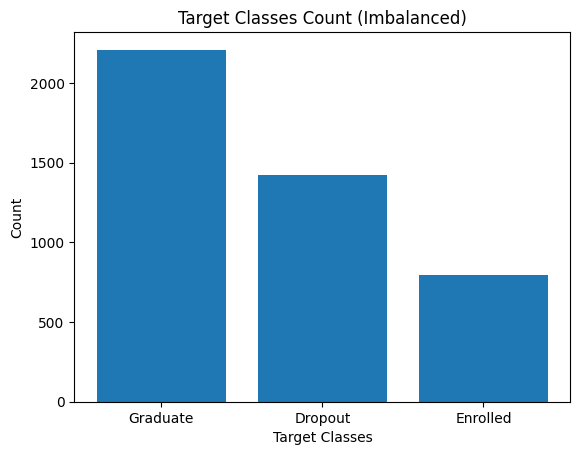

In [ ]:
#plot data instances
import matplotlib.pyplot as plt

#plot imbalanced dataset
plt.figure()
plt.bar(data['Target'].value_counts().index, data["Target"].value_counts().values)
plt.xlabel("Target Classes")
plt.ylabel("Count")
plt.title("Target Classes Count (Imbalanced)")

plt.show()


**Balancing- Undersampling**

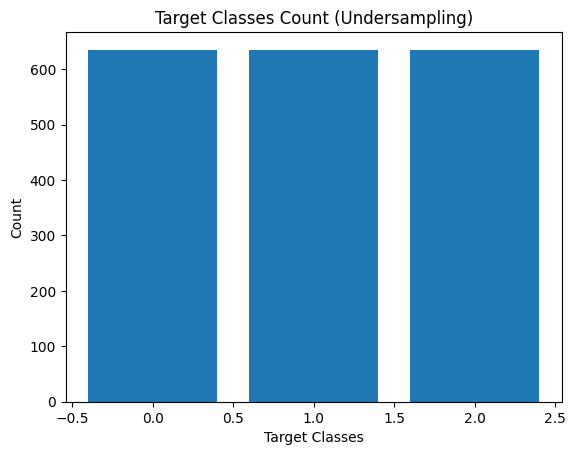

In [ ]:
#data balancing undersampling

new_undersampled=pd.Series(y_resampled_under).value_counts()

#plot undersampled dataset
plt.figure()
plt.bar(new_undersampled.index, new_undersampled.values)
plt.xlabel("Target Classes")
plt.ylabel("Count")
plt.title("Target Classes Count (Undersampling)")

plt.show()

**Balancing- SMOTE**

Text(0.5, 1.0, 'Target Classes Count (SMOTE)')

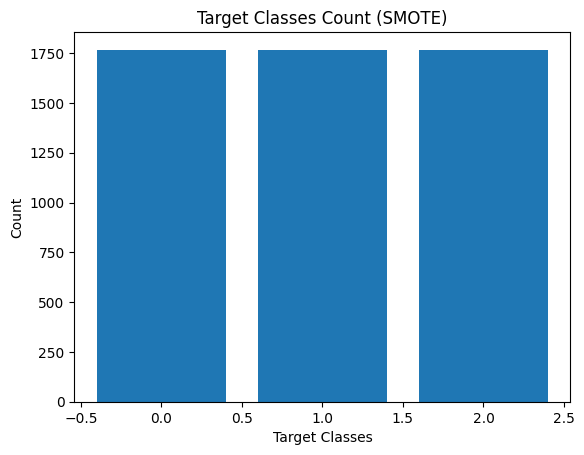

In [ ]:
#data balancing SMOTE

new_smote=pd.Series(y_resampled_smote).value_counts()

#plot smote dataset
plt.figure()
plt.bar(new_smote.index, new_smote.values)
plt.xlabel("Target Classes")
plt.ylabel("Count")
plt.title("Target Classes Count (SMOTE)")


### **MLP Model (Multiple Perceptron)**

Deeper Network (7 layers with ReLU)

In [ ]:
#creating MLP model
from sklearn.neural_network import MLPClassifier

#model has 7 hidden layers
#uses activation function relu
#learning rate is set to 0.01
#maximum number of iterations for the model is 100
#random state 42 to get same results
#regularization technique early stopping is used
#mini-batch gradient samples is set to 400 samples

student_academic_success_model_1=MLPClassifier(
    hidden_layer_sizes=(450,225,100,100,50,20,10,),
    activation='relu',
    learning_rate_init=0.01,
    max_iter=100,
    random_state=42,
    early_stopping=True,
    batch_size=400


)

Deeper Network (7 layers with Tanh)

In [ ]:
#deep network but with tanh activation function

student_academic_success_model_1t=MLPClassifier(
    hidden_layer_sizes=(450,225,100,100,50,20,10,),
    activation='tanh',
    learning_rate_init=0.01,
    max_iter=100,
    random_state=42,
    early_stopping=True,
    batch_size=400


)

Wider Network (2 layers with ReLU)

In [ ]:
#model has 2 hidden layers
#uses activation function relu
#learning rate is set to 0.01
#maximum number of iterations for the model is 100
#random state 42 to get same results
#regularization technique early stopping is used
#mini-batch gradient samples is set to 400 samples


student_academic_success_model_2=MLPClassifier(
    hidden_layer_sizes=(450,50,),
    activation='relu',
    learning_rate_init=0.01,
    max_iter=100,
    random_state=42,
    early_stopping=True,
    batch_size=400


)

Wider Network (2 layers with Tanh)

In [ ]:
#wide network but with tanh activation function

student_academic_success_model_2t=MLPClassifier(
    hidden_layer_sizes=(450,50,),
    activation='tanh',
    learning_rate_init=0.01,
    max_iter=100,
    random_state=42,
    early_stopping=True,
    batch_size=400


)

**Imbalanced Data Results**

Training the models with ReLU

In [ ]:
#models with relu activation function

#1) Deeper Network
#training the model
student_academic_success_model_1.fit(X_train, y_train)

#checking accuracy on training and testing data
train_acc=student_academic_success_model_1.score(X_train, y_train)
test_acc=student_academic_success_model_1.score(X_test, y_test)

#printing the accuracy scores
print(f"Deeper Network Model relu: train={train_acc:.3f}, test={test_acc:.3f}, loss={student_academic_success_model_1.loss_:.4f}, iters={student_academic_success_model_1.n_iter_}")


#2) Wider Network
#training the model
student_academic_success_model_2.fit(X_train, y_train)

#checking accuracy on training and testing data
train_acc=student_academic_success_model_2.score(X_train, y_train)
test_acc=student_academic_success_model_2.score(X_test, y_test)

#printing the accuracy scores
print(f"Wider Network Model relu: train={train_acc:.3f}, test={test_acc:.3f}, loss={student_academic_success_model_2.loss_:.4f}, iters={student_academic_success_model_2.n_iter_}")

Deeper Network Model relu: train=0.856, test=0.765, loss=0.1041, iters=17
Wider Network Model relu: train=0.871, test=0.766, loss=0.0826, iters=17


Training the models with Tanh

In [ ]:
#models with tanh activation function

#1) Deeper Network
#training the model
student_academic_success_model_1t.fit(X_train, y_train)

#checking accuracy on training and testing data
train_acc=student_academic_success_model_1t.score(X_train, y_train)
test_acc=student_academic_success_model_1t.score(X_test, y_test)

#printing the accuracy scores
print(f"Deeper Network Model tanh: train={train_acc:.3f}, test={test_acc:.3f}, loss={student_academic_success_model_1t.loss_:.4f}, iters={student_academic_success_model_1t.n_iter_}")


#2) Wider Network
#training the model
student_academic_success_model_2t.fit(X_train, y_train)

#checking accuracy on training and testing data
train_acc=student_academic_success_model_2t.score(X_train, y_train)
test_acc=student_academic_success_model_2t.score(X_test, y_test)

#printing the accuracy scores
print(f"Wider Network Model tanh: train={train_acc:.3f}, test={test_acc:.3f}, loss={student_academic_success_model_2t.loss_:.4f}, iters={student_academic_success_model_2t.n_iter_}")

Deeper Network Model tanh: train=0.907, test=0.718, loss=0.1464, iters=26
Wider Network Model tanh: train=0.914, test=0.733, loss=0.0357, iters=18


Checking loss with ReLU models

In [ ]:
#models with relu activation function

#using evaluation metrics to measure performance
from sklearn.metrics import log_loss, confusion_matrix, classification_report

#1) Deeper Network
#getting predictions from training
y_pred_train_1=student_academic_success_model_1.predict_proba(X_train)
y_pred_train_labels_1=np.argmax(y_pred_train_1, axis=1)
train_loss_1=log_loss(y_train, y_pred_train_1)

#getting predictions from testing
y_pred_test_1=student_academic_success_model_1.predict_proba(X_test)
y_pred_test_labels_1=np.argmax(y_pred_test_1, axis=1)
test_loss_1=log_loss(y_test, y_pred_test_1)

#printing the total loss for both training and testing
print(f"Training loss Deeper Network relu: {train_loss_1:.5f}")
print(f"Testing loss Deeper Network relu: {test_loss_1:.5f}")


#2) Wider Network
#getting predictions from training
y_pred_train_2=student_academic_success_model_2.predict_proba(X_train)
y_pred_train_labels_2=np.argmax(y_pred_train_2, axis=1)
train_loss_2=log_loss(y_train, y_pred_train_2)

#getting predictions from testing
y_pred_test_2=student_academic_success_model_2.predict_proba(X_test)
y_pred_test_labels_2=np.argmax(y_pred_test_2, axis=1)
test_loss_2=log_loss(y_test, y_pred_test_2)

#printing the total loss for both training and testing
print()
print(f"Training loss Wider Network relu: {train_loss_2:.5f}")
print(f"Testing loss Wider Network relu: {test_loss_2:.5f}")


Training loss Deeper Network relu: 0.41679
Testing loss Deeper Network relu: 0.91384

Training loss Wider Network relu: 0.35391
Testing loss Wider Network relu: 0.86254


Checking loss with Tanh models

In [ ]:
#models with tanh activation function

#using evaluation metrics to measure performance

#1) Deeper Network
#getting predictions from training
y_pred_train_1t=student_academic_success_model_1t.predict_proba(X_train)
y_pred_train_labels_1t=np.argmax(y_pred_train_1t, axis=1)
train_loss_1t=log_loss(y_train, y_pred_train_1t)

#getting predictions from testing
y_pred_test_1t=student_academic_success_model_1t.predict_proba(X_test)
y_pred_test_labels_1t=np.argmax(y_pred_test_1t, axis=1)
test_loss_1t=log_loss(y_test, y_pred_test_1t)

#printing the total loss for both training and testing
print(f"Training loss Deeper Network tanh: {train_loss_1t:.5f}")
print(f"Testing loss Deeper Network tanh: {test_loss_1t:.5f}")


#2) Wider Network
#getting predictions from training
y_pred_train_2t=student_academic_success_model_2t.predict_proba(X_train)
y_pred_train_labels_2t=np.argmax(y_pred_train_2t, axis=1)
train_loss_2t=log_loss(y_train, y_pred_train_2t)

#getting predictions from testing
y_pred_test_2t=student_academic_success_model_2t.predict_proba(X_test)
y_pred_test_labels_2t=np.argmax(y_pred_test_2t, axis=1)
test_loss_2t=log_loss(y_test, y_pred_test_2t)

#printing the total loss for both training and testing
print()
print(f"Training loss Wider Network tanh: {train_loss_2t:.5f}")
print(f"Testing loss Wider Network tanh: {test_loss_2t:.5f}")


Training loss Deeper Network tanh: 0.29481
Testing loss Deeper Network tanh: 0.90937

Training loss Wider Network tanh: 0.27804
Testing loss Wider Network tanh: 0.76004


ReLU training confusion matrix

In [ ]:
#confusion matrix for training predictions in imbalanced dataset (relu)

#1) Deeper Network
conf_mlp_1=confusion_matrix(y_train, y_pred_train_labels_1)
print(conf_mlp_1)

print()

#2) Wider Network
conf_mlp_2=confusion_matrix(y_train, y_pred_train_labels_2)
print(conf_mlp_2)

[[1694    9   64]
 [  88  920  129]
 [ 132   87  416]]

[[1732   18   17]
 [ 106  993   38]
 [ 184   93  358]]


Tanh training confusion matrix



In [ ]:
#confusion matrix for training predictions in imbalanced dataset (tanh)

#1) Deeper Network
conf_mlp_1t=confusion_matrix(y_train, y_pred_train_labels_1t)
print(conf_mlp_1t)

print()

#2) Wider Network
conf_mlp_2t=confusion_matrix(y_train, y_pred_train_labels_2t)
print(conf_mlp_2t)

[[1660   55   52]
 [  70 1030   37]
 [  54   62  519]]

[[1698   29   40]
 [  76 1022   39]
 [  76   43  516]]


ReLU testing confusion matrix

In [ ]:
#confusion matrix for testing predictions in imbalanced dataset (relu)

#1) Deeper Network
conf_mlp_1=confusion_matrix(y_test, y_pred_test_labels_1)
print(conf_mlp_1)

print()

#2) Wider Network
conf_mlp_2=confusion_matrix(y_test, y_pred_test_labels_2)
print(conf_mlp_2)

[[387  15  40]
 [ 22 221  41]
 [ 55  35  69]]

[[399  21  22]
 [ 30 229  25]
 [ 66  43  50]]


Tanh testing confusion matrix

In [ ]:
#confusion matrix for training predictions in imbalanced dataset (tanh)

#1) Deeper Network
conf_mlp_1t=confusion_matrix(y_test, y_pred_test_labels_1t)
print(conf_mlp_1t)

print()

#2) Wider Network
conf_mlp_2t=confusion_matrix(y_test, y_pred_test_labels_2t)
print(conf_mlp_2t)

[[353  39  50]
 [ 22 225  37]
 [ 49  53  57]]

[[368  38  36]
 [ 19 223  42]
 [ 53  48  58]]


ReLU testing confusion matrix PLOT

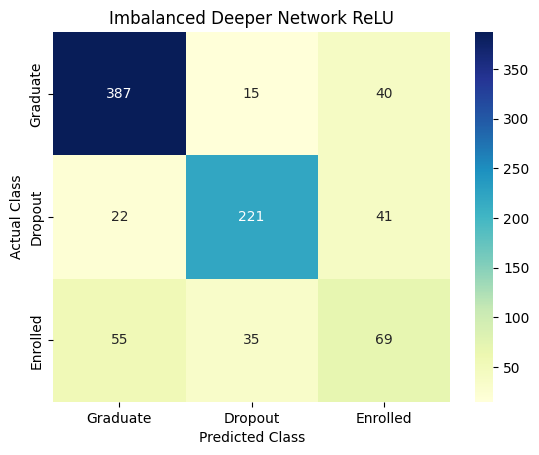

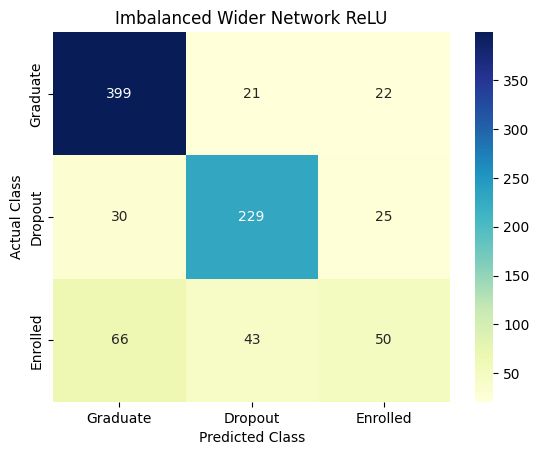

In [ ]:
import seaborn as sns # for statistical data visualization

#confusion matrix plot (relu)

class_names = ["Graduate", "Dropout", "Enrolled"]

#1) Deeper Network confusion matrix plot
conf_1_matrix = pd.DataFrame(data=conf_mlp_1, columns=class_names, index=class_names)

sns.heatmap(conf_1_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Imbalanced Deeper Network ReLU")
plt.show()

print()

#2) Wider Network confusion matrix plot
conf_2_matrix = pd.DataFrame(data=conf_mlp_2, columns=class_names, index=class_names)

sns.heatmap(conf_2_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Imbalanced Wider Network ReLU")
plt.show()

Tanh testing confusion matrix PLOT

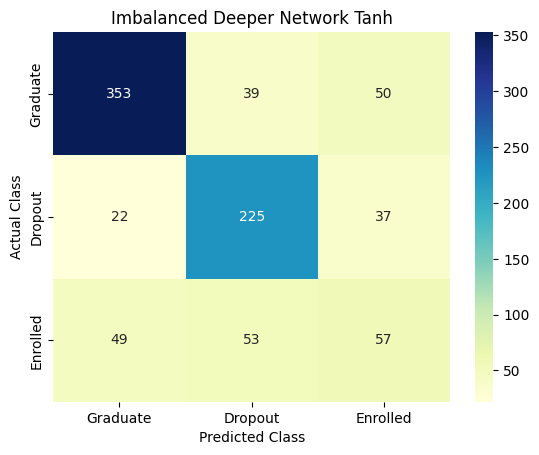

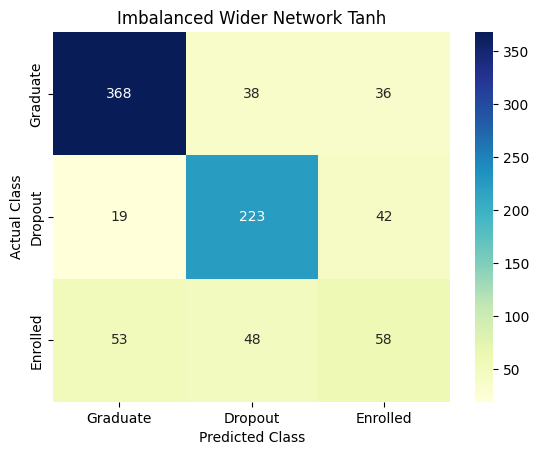

In [ ]:
#confusion matrix plot (tanh)

class_names = ["Graduate", "Dropout", "Enrolled"]

#1) Deeper Network confusion matrix plot
conf_1_matrix = pd.DataFrame(data=conf_mlp_1t, columns=class_names, index=class_names)

sns.heatmap(conf_1_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Imbalanced Deeper Network Tanh")
plt.show()

print()

#2) Wider Network confusion matrix plot
conf_2_matrix = pd.DataFrame(data=conf_mlp_2t, columns=class_names, index=class_names)

sns.heatmap(conf_2_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Imbalanced Wider Network Tanh")
plt.show()

ReLU training classification report

In [ ]:
#classification report for training set (relu)

#1) Deeper Network
classif_rep=classification_report(y_train, y_pred_train_labels_1)
print(classif_rep)

print()

#2) Wider Network
classif_rep=classification_report(y_train, y_pred_train_labels_2)
print(classif_rep)

              precision    recall  f1-score   support

           0       0.89      0.96      0.92      1767
           1       0.91      0.81      0.85      1137
           2       0.68      0.66      0.67       635

    accuracy                           0.86      3539
   macro avg       0.82      0.81      0.81      3539
weighted avg       0.86      0.86      0.85      3539


              precision    recall  f1-score   support

           0       0.86      0.98      0.91      1767
           1       0.90      0.87      0.89      1137
           2       0.87      0.56      0.68       635

    accuracy                           0.87      3539
   macro avg       0.87      0.81      0.83      3539
weighted avg       0.87      0.87      0.86      3539



Tanh training classification report

In [ ]:
#classification report for training set (tanh)

#1) Deeper Network
classif_rep=classification_report(y_train, y_pred_train_labels_1t)
print(classif_rep)

print()

#2) Wider Network
classif_rep=classification_report(y_train, y_pred_train_labels_2t)
print(classif_rep)

              precision    recall  f1-score   support

           0       0.93      0.94      0.93      1767
           1       0.90      0.91      0.90      1137
           2       0.85      0.82      0.84       635

    accuracy                           0.91      3539
   macro avg       0.89      0.89      0.89      3539
weighted avg       0.91      0.91      0.91      3539


              precision    recall  f1-score   support

           0       0.92      0.96      0.94      1767
           1       0.93      0.90      0.92      1137
           2       0.87      0.81      0.84       635

    accuracy                           0.91      3539
   macro avg       0.91      0.89      0.90      3539
weighted avg       0.91      0.91      0.91      3539



ReLU testing classification report

In [ ]:
#classification report for testing set (relu)

#1) Deeper Network
classif_rep_1=classification_report(y_test, y_pred_test_labels_1)
print(classif_rep_1)

print()

#2) Wider Network
classif_rep_2=classification_report(y_test, y_pred_test_labels_2)
print(classif_rep_2)

              precision    recall  f1-score   support

           0       0.83      0.88      0.85       442
           1       0.82      0.78      0.80       284
           2       0.46      0.43      0.45       159

    accuracy                           0.76       885
   macro avg       0.70      0.70      0.70       885
weighted avg       0.76      0.76      0.76       885


              precision    recall  f1-score   support

           0       0.81      0.90      0.85       442
           1       0.78      0.81      0.79       284
           2       0.52      0.31      0.39       159

    accuracy                           0.77       885
   macro avg       0.70      0.67      0.68       885
weighted avg       0.75      0.77      0.75       885



Tanh testing classification report

In [ ]:
#classification report for testing set (tanh)

#1) Deeper Network
classif_rep_1=classification_report(y_test, y_pred_test_labels_1t)
print(classif_rep_1)

print()

#2) Wider Network
classif_rep_2=classification_report(y_test, y_pred_test_labels_2t)
print(classif_rep_2)

              precision    recall  f1-score   support

           0       0.83      0.80      0.82       442
           1       0.71      0.79      0.75       284
           2       0.40      0.36      0.38       159

    accuracy                           0.72       885
   macro avg       0.65      0.65      0.65       885
weighted avg       0.71      0.72      0.72       885


              precision    recall  f1-score   support

           0       0.84      0.83      0.83       442
           1       0.72      0.79      0.75       284
           2       0.43      0.36      0.39       159

    accuracy                           0.73       885
   macro avg       0.66      0.66      0.66       885
weighted avg       0.73      0.73      0.73       885



ReLU training loss CURVE

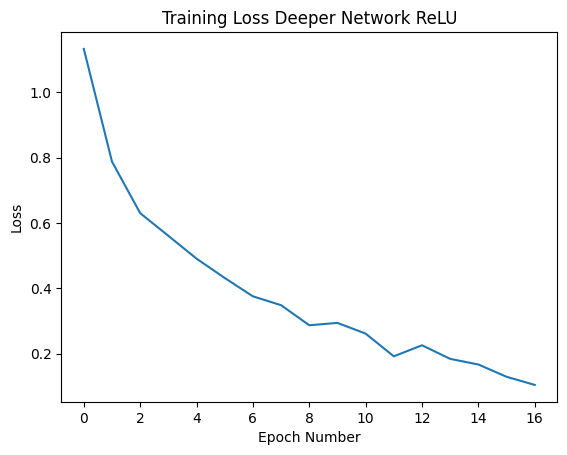

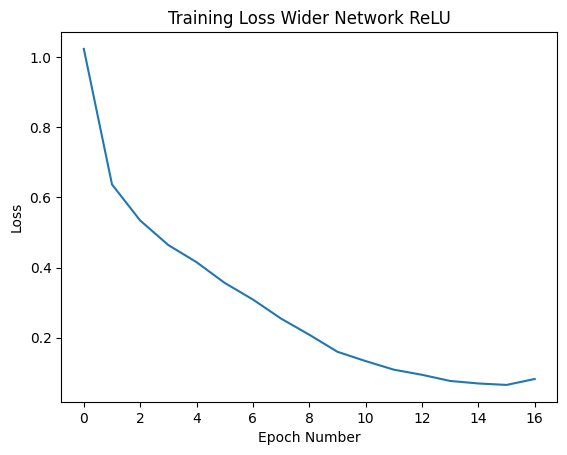

In [ ]:
#model training loss for imbalanced data

#1) Deeper Network
plt.plot(student_academic_success_model_1.loss_curve_)
plt.title("Training Loss Deeper Network ReLU")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()

print()

#2) Wider Network
plt.plot(student_academic_success_model_2.loss_curve_)
plt.title("Training Loss Wider Network ReLU")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()

Tanh training loss CURVE

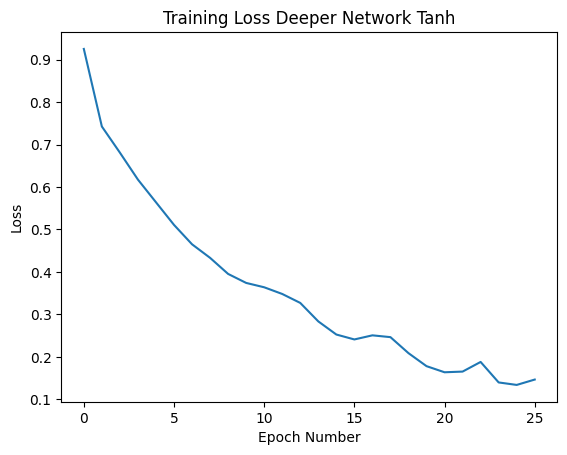

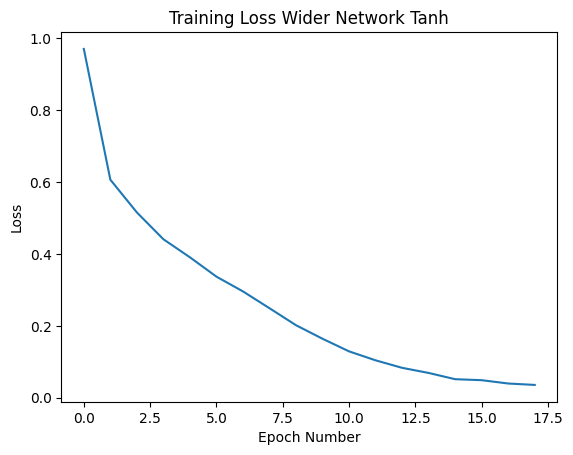

In [ ]:
#model training loss for imbalanced data

#1) Deeper Network
plt.plot(student_academic_success_model_1t.loss_curve_)
plt.title("Training Loss Deeper Network Tanh")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()

print()

#2) Wider Network
plt.plot(student_academic_success_model_2t.loss_curve_)
plt.title("Training Loss Wider Network Tanh")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()

.

**Undersampling Data Results**

Training models with ReLU (undersampled)

In [ ]:
#models with relu activation function

#1) Deeper Network
#training the model on undersampled data
student_academic_success_model_1.fit(X_train_under, y_resampled_under)

#getting training and testing for the undersampled data
train_acc_under=student_academic_success_model_1.score(X_train_under, y_resampled_under)
test_acc_under=student_academic_success_model_1.score(X_test, y_test)

#printing the training and testing accuracy scores based on the undersampled data
print(f"Deeper Network Model relu: train={train_acc_under:.3f}, test={test_acc_under:.3f}, loss={student_academic_success_model_1.loss_:.4f}, iters={student_academic_success_model_1.n_iter_}")


#2) Wider Network
#training the model on undersampled data
student_academic_success_model_2.fit(X_train_under, y_resampled_under)

#getting training and testing for the undersampled data
train_acc_under=student_academic_success_model_2.score(X_train_under, y_resampled_under)
test_acc_under=student_academic_success_model_2.score(X_test, y_test)

#printing the training and testing accuracy scores based on the undersampled data
print(f"Wider Network Model relu: train={train_acc_under:.3f}, test={test_acc_under:.3f}, loss={student_academic_success_model_2.loss_:.4f}, iters={student_academic_success_model_2.n_iter_}")

Deeper Network Model relu: train=0.847, test=0.668, loss=0.1619, iters=19
Wider Network Model relu: train=0.915, test=0.618, loss=0.0321, iters=22


Training models with Tanh (undersampled)

In [ ]:
#models with tanh activation function

#1) Deeper Network
#training the model on undersampled data
student_academic_success_model_1t.fit(X_train_under, y_resampled_under)

#getting training and testing for the undersampled data
train_acc_under=student_academic_success_model_1t.score(X_train_under, y_resampled_under)
test_acc_under=student_academic_success_model_1t.score(X_test, y_test)

#printing the training and testing accuracy scores based on the undersampled data
print(f"Deeper Network Model tanh: train={train_acc_under:.3f}, test={test_acc_under:.3f}, loss={student_academic_success_model_1t.loss_:.4f}, iters={student_academic_success_model_1t.n_iter_}")


#2) Wider Network
#training the model on undersampled data
student_academic_success_model_2t.fit(X_train_under, y_resampled_under)

#getting training and testing for the undersampled data
train_acc_under=student_academic_success_model_2t.score(X_train_under, y_resampled_under)
test_acc_under=student_academic_success_model_2t.score(X_test, y_test)

#printing the training and testing accuracy scores based on the undersampled data
print(f"Wider Network Model tanh: train={train_acc_under:.3f}, test={test_acc_under:.3f}, loss={student_academic_success_model_2t.loss_:.4f}, iters={student_academic_success_model_2t.n_iter_}")

Deeper Network Model tanh: train=0.901, test=0.600, loss=0.1612, iters=31
Wider Network Model tanh: train=0.840, test=0.652, loss=0.0726, iters=16


Checking loss with ReLU models (undersampled)

In [ ]:
#1) Deeper Network
#training predictions with undersampled data
y_pred_train_1=student_academic_success_model_1.predict_proba(X_train_under)
y_pred_train_labels_1=np.argmax(y_pred_train_1, axis=1)
train_loss_1=log_loss(y_resampled_under, y_pred_train_1)

#testing predictions with the model trained based on undersampled data
y_pred_test_1=student_academic_success_model_1.predict_proba(X_test)
y_pred_test_labels_1=np.argmax(y_pred_test_1, axis=1)
test_loss_1=log_loss(y_test, y_pred_test_1)

#printing training and testing losses
print(f"Training loss Deeper Network relu: {train_loss_1:.5f}")
print(f"Testing loss Deeper Network relu: {test_loss_1:.5f}")

print()

#2) Wider Network
#training predictions with undersampled data
y_pred_train_2=student_academic_success_model_2.predict_proba(X_train_under)
y_pred_train_labels_2=np.argmax(y_pred_train_2, axis=1)
train_loss_2=log_loss(y_resampled_under, y_pred_train_2)

#testing predictions with the model trained based on undersampled data
y_pred_test_2=student_academic_success_model_2.predict_proba(X_test)
y_pred_test_labels_2=np.argmax(y_pred_test_2, axis=1)
test_loss_2=log_loss(y_test, y_pred_test_2)

#printing training and testing losses
print(f"Training loss Wider Network relu: {train_loss_2:.5f}")
print(f"Testing loss Wider Network relu: {test_loss_2:.5f}")


Training loss Deeper Network relu: 0.46052
Testing loss Deeper Network relu: 1.18589

Training loss Wider Network relu: 0.27519
Testing loss Wider Network relu: 1.47956


Checking loss with Tanh models (undersampled)

In [ ]:
#1) Deeper Network
#training predictions with undersampled data
y_pred_train_1t=student_academic_success_model_1t.predict_proba(X_train_under)
y_pred_train_labels_1t=np.argmax(y_pred_train_1t, axis=1)
train_loss_1t=log_loss(y_resampled_under, y_pred_train_1t)

#testing predictions with the model trained based on undersampled data
y_pred_test_1t=student_academic_success_model_1t.predict_proba(X_test)
y_pred_test_labels_1t=np.argmax(y_pred_test_1t, axis=1)
test_loss_1t=log_loss(y_test, y_pred_test_1t)

#printing training and testing losses
print(f"Training loss Deeper Network tanh: {train_loss_1t:.5f}")
print(f"Testing loss Deeper Network tanh: {test_loss_1t:.5f}")

print()

#2) Wider Network
#training predictions with undersampled data
y_pred_train_2t=student_academic_success_model_2t.predict_proba(X_train_under)
y_pred_train_labels_2t=np.argmax(y_pred_train_2t, axis=1)
train_loss_2t=log_loss(y_resampled_under, y_pred_train_2t)

#testing predictions with the model trained based on undersampled data
y_pred_test_2t=student_academic_success_model_2t.predict_proba(X_test)
y_pred_test_labels_2t=np.argmax(y_pred_test_2t, axis=1)
test_loss_2t=log_loss(y_test, y_pred_test_2t)

#printing training and testing losses
print(f"Training loss Wider Network tanh: {train_loss_2t:.5f}")
print(f"Testing loss Wider Network tanh: {test_loss_2t:.5f}")


Training loss Deeper Network tanh: 0.32201
Testing loss Deeper Network tanh: 1.18259

Training loss Wider Network tanh: 0.46633
Testing loss Wider Network tanh: 0.83485


ReLU training confusion matrix (undersampled)

In [ ]:
#confusion matrix for training based on undersampled data

#1) Deeper Network
conf_mlp_1=confusion_matrix(y_resampled_under, y_pred_train_labels_1)
print(conf_mlp_1)

print()

#2) Wider Network
conf_mlp_2=confusion_matrix(y_resampled_under, y_pred_train_labels_2)
print(conf_mlp_2)

[[590   7  38]
 [ 55 522  58]
 [ 73  60 502]]

[[595  10  30]
 [ 45 552  38]
 [ 20  19 596]]


Tanh training confusion matrix (undersampled)

In [ ]:
#confusion matrix for training based on undersampled data

#1) Deeper Network
conf_mlp_1t=confusion_matrix(y_resampled_under, y_pred_train_labels_1t)
print(conf_mlp_1t)

print()

#2) Wider Network
conf_mlp_2t=confusion_matrix(y_resampled_under, y_pred_train_labels_2t)
print(conf_mlp_2t)

[[597   9  29]
 [ 27 557  51]
 [ 31  41 563]]

[[578  14  43]
 [ 53 524  58]
 [ 80  57 498]]


ReLU testing confusion matrix (undersampled)

In [ ]:
#confusion matrix of the testing results as the model was trained on undersampled data

#1) Deeper Network
conf_mlp_1=confusion_matrix(y_test, y_pred_test_labels_1)
print(conf_mlp_1)

print()

#2) Wider Network
conf_mlp_2=confusion_matrix(y_test, y_pred_test_labels_2)
print(conf_mlp_2)

[[284  29 129]
 [ 14 218  52]
 [ 38  32  89]]

[[256  36 150]
 [ 12 202  70]
 [ 34  36  89]]


Tanh testing confusion matrix (undersampled)

In [ ]:
#confusion matrix of the testing results as the model was trained on undersampled data

#1) Deeper Network
conf_mlp_1t=confusion_matrix(y_test, y_pred_test_labels_1t)
print(conf_mlp_1t)

print()

#2) Wider Network
conf_mlp_2t=confusion_matrix(y_test, y_pred_test_labels_2t)
print(conf_mlp_2t)

[[238  52 152]
 [ 15 210  59]
 [ 33  43  83]]

[[279  47 116]
 [ 18 215  51]
 [ 34  42  83]]


ReLU confusion matrix PLOT (undersampled)

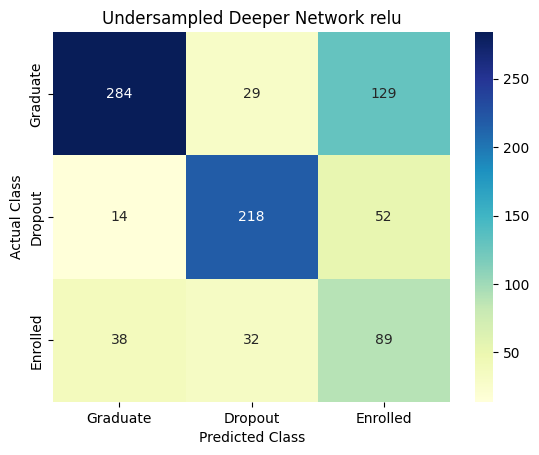

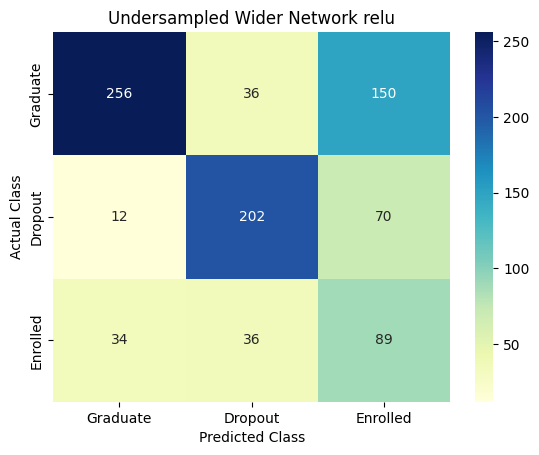

In [ ]:
import seaborn as sns # for statistical data visualization

class_names = ["Graduate", "Dropout", "Enrolled"]

#1) Deeper Network
conf_1_matrix = pd.DataFrame(data=conf_mlp_1, columns=class_names, index=class_names)

sns.heatmap(conf_1_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Undersampled Deeper Network relu")
plt.show()

print()

#2) Wider Network
conf_2_matrix = pd.DataFrame(data=conf_mlp_2, columns=class_names, index=class_names)

sns.heatmap(conf_2_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Undersampled Wider Network relu")
plt.show()

Tanh confusion matrix PLOT (undersampled)

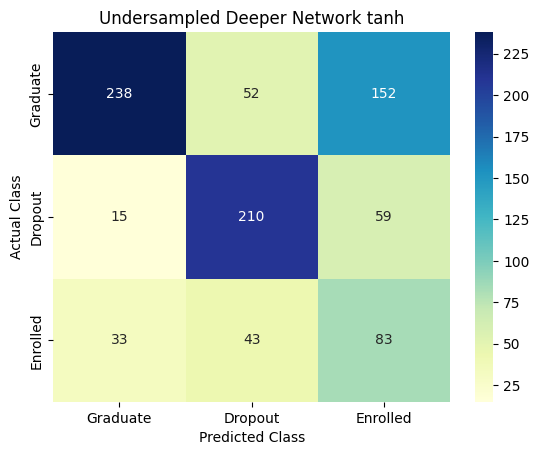

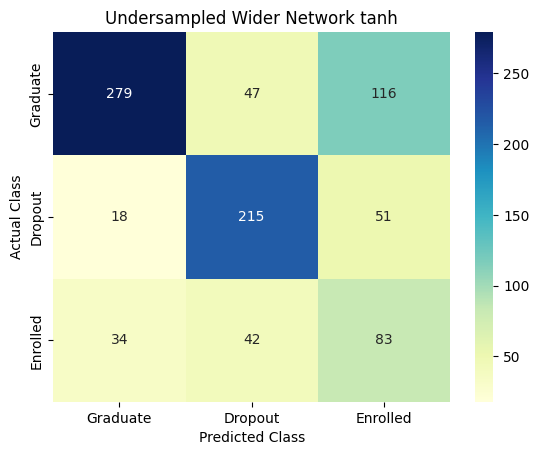

In [ ]:
class_names = ["Graduate", "Dropout", "Enrolled"]

#1) Deeper Network
conf_1_matrix = pd.DataFrame(data=conf_mlp_1t, columns=class_names, index=class_names)

sns.heatmap(conf_1_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Undersampled Deeper Network tanh")
plt.show()

print()

#2) Wider Network
conf_2_matrix = pd.DataFrame(data=conf_mlp_2t, columns=class_names, index=class_names)

sns.heatmap(conf_2_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("Undersampled Wider Network tanh")
plt.show()

ReLU training classification report (undersampled)

In [ ]:
#classification report for training on undersampled data

#1) Deeper Network
classif_rep_1=classification_report(y_resampled_under, y_pred_train_labels_1)
print(classif_rep_1)

print()

#2) Wider Network
classif_rep_2=classification_report(y_resampled_under, y_pred_train_labels_2)
print(classif_rep_2)

              precision    recall  f1-score   support

           0       0.82      0.93      0.87       635
           1       0.89      0.82      0.85       635
           2       0.84      0.79      0.81       635

    accuracy                           0.85      1905
   macro avg       0.85      0.85      0.85      1905
weighted avg       0.85      0.85      0.85      1905


              precision    recall  f1-score   support

           0       0.90      0.94      0.92       635
           1       0.95      0.87      0.91       635
           2       0.90      0.94      0.92       635

    accuracy                           0.91      1905
   macro avg       0.92      0.91      0.91      1905
weighted avg       0.92      0.91      0.91      1905



Tanh training classification report (undersampled)

In [ ]:
#classification report for training on undersampled data

#1) Deeper Network
classif_rep_1=classification_report(y_resampled_under, y_pred_train_labels_1t)
print(classif_rep_1)

print()

#2) Wider Network
classif_rep_2=classification_report(y_resampled_under, y_pred_train_labels_2t)
print(classif_rep_2)

              precision    recall  f1-score   support

           0       0.91      0.94      0.93       635
           1       0.92      0.88      0.90       635
           2       0.88      0.89      0.88       635

    accuracy                           0.90      1905
   macro avg       0.90      0.90      0.90      1905
weighted avg       0.90      0.90      0.90      1905


              precision    recall  f1-score   support

           0       0.81      0.91      0.86       635
           1       0.88      0.83      0.85       635
           2       0.83      0.78      0.81       635

    accuracy                           0.84      1905
   macro avg       0.84      0.84      0.84      1905
weighted avg       0.84      0.84      0.84      1905



ReLU testing classification report (undersampled)

In [ ]:
#classification report for testing after training on undersampled data

#1) Deeper Network
classif_rep_1=classification_report(y_test, y_pred_test_labels_1)
print(classif_rep_1)

print()

#2) Wider Network
classif_rep_2=classification_report(y_test, y_pred_test_labels_2)
print(classif_rep_2)

              precision    recall  f1-score   support

           0       0.85      0.64      0.73       442
           1       0.78      0.77      0.77       284
           2       0.33      0.56      0.41       159

    accuracy                           0.67       885
   macro avg       0.65      0.66      0.64       885
weighted avg       0.73      0.67      0.69       885


              precision    recall  f1-score   support

           0       0.85      0.58      0.69       442
           1       0.74      0.71      0.72       284
           2       0.29      0.56      0.38       159

    accuracy                           0.62       885
   macro avg       0.62      0.62      0.60       885
weighted avg       0.71      0.62      0.64       885



Tanh testing classification report (undersampled)

In [ ]:
#classification report for testing after training on undersampled data

#1) Deeper Network
classif_rep_1=classification_report(y_test, y_pred_test_labels_1t)
print(classif_rep_1)

print()

#2) Wider Network
classif_rep_2=classification_report(y_test, y_pred_test_labels_2t)
print(classif_rep_2)

              precision    recall  f1-score   support

           0       0.83      0.54      0.65       442
           1       0.69      0.74      0.71       284
           2       0.28      0.52      0.37       159

    accuracy                           0.60       885
   macro avg       0.60      0.60      0.58       885
weighted avg       0.69      0.60      0.62       885


              precision    recall  f1-score   support

           0       0.84      0.63      0.72       442
           1       0.71      0.76      0.73       284
           2       0.33      0.52      0.41       159

    accuracy                           0.65       885
   macro avg       0.63      0.64      0.62       885
weighted avg       0.71      0.65      0.67       885



ReLU training loss CURVE (undersampled)

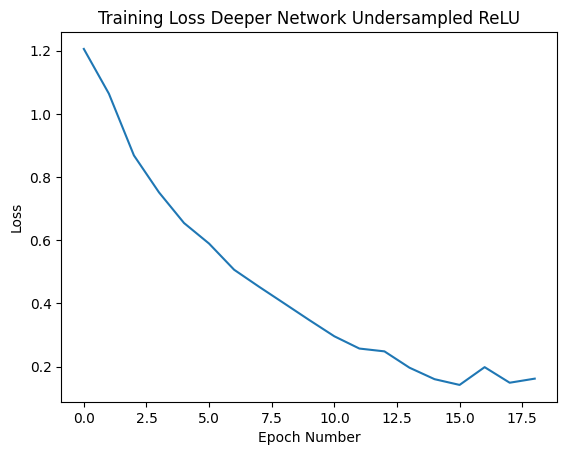

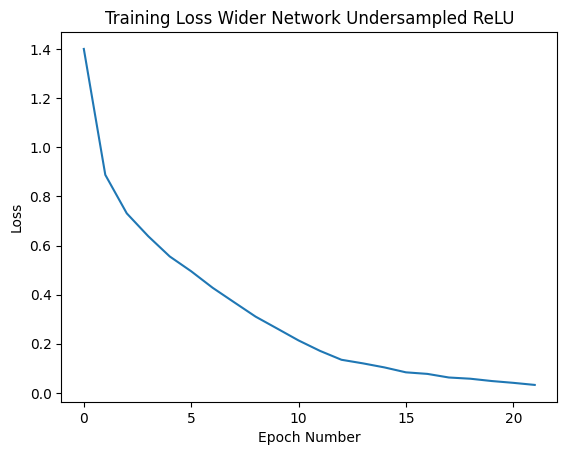

In [ ]:
#training loss on undersampled data

#1) Deeper Network
plt.plot(student_academic_success_model_1.loss_curve_)
plt.title("Training Loss Deeper Network Undersampled ReLU")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()

print()

#2) Wider Network
plt.plot(student_academic_success_model_2.loss_curve_)
plt.title("Training Loss Wider Network Undersampled ReLU")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()

Tanh training loss CURVE (undersampled)

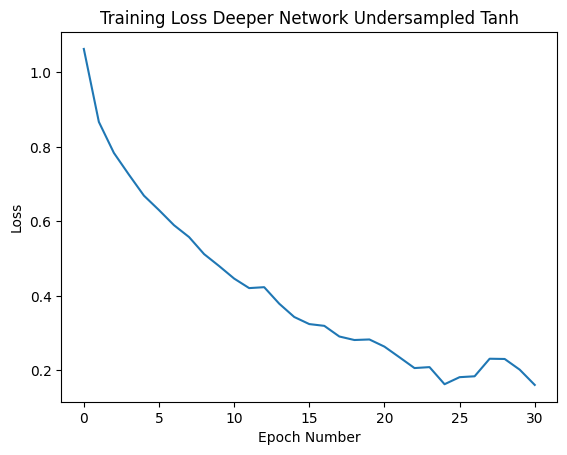

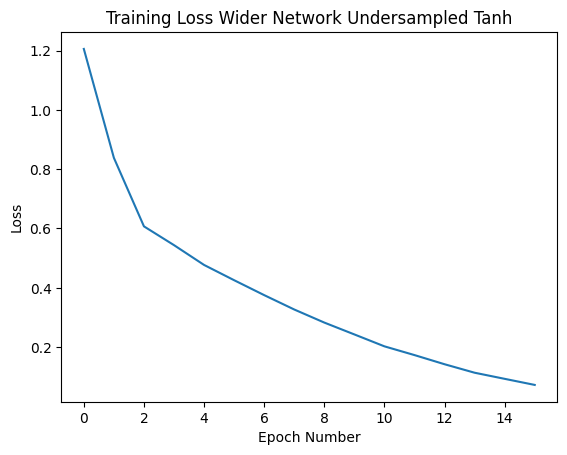

In [ ]:
#training loss on undersampled data (tanh)

#1) Deeper Network
plt.plot(student_academic_success_model_1t.loss_curve_)
plt.title("Training Loss Deeper Network Undersampled Tanh")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()

print()

#2) Wider Network
plt.plot(student_academic_success_model_2t.loss_curve_)
plt.title("Training Loss Wider Network Undersampled Tanh")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()

.

**SMOTE Data Results**

Training models with ReLU (SMOTE)

In [ ]:
#models with relu activation function

#1) Deeper Network
#model trained on smote data
student_academic_success_model_1.fit(X_train_smote, y_resampled_smote)

#getting training and testing accuracy for smote data
train_acc_smote=student_academic_success_model_1.score(X_train_smote, y_resampled_smote)
test_acc_smote=student_academic_success_model_1.score(X_test, y_test)

#printing the training and testing accuracies
print(f"Deeper Network Model relu: train={train_acc_smote:.3f}, test={test_acc_smote:.3f}, loss={student_academic_success_model_1.loss_:.4f}, iters={student_academic_success_model_1.n_iter_}")


#2) Wider Network
#model trained on smote data
student_academic_success_model_2.fit(X_train_smote, y_resampled_smote)

#getting training and testing accuracy for smote data
train_acc_smote=student_academic_success_model_2.score(X_train_smote, y_resampled_smote)
test_acc_smote=student_academic_success_model_2.score(X_test, y_test)

#printing the training and testing accuracies
print(f"Wider Network Model relu: train={train_acc_smote:.3f}, test={test_acc_smote:.3f}, loss={student_academic_success_model_2.loss_:.4f}, iters={student_academic_success_model_2.n_iter_}")

Deeper Network Model relu: train=0.954, test=0.659, loss=0.0451, iters=20
Wider Network Model relu: train=0.976, test=0.684, loss=0.0641, iters=23


Training models with Tanh (SMOTE)

In [ ]:
#models with tanh activation function

#1) Deeper Network
#model trained on smote data
student_academic_success_model_1t.fit(X_train_smote, y_resampled_smote)

#getting training and testing accuracy for smote data
train_acc_smote=student_academic_success_model_1t.score(X_train_smote, y_resampled_smote)
test_acc_smote=student_academic_success_model_1t.score(X_test, y_test)

#printing the training and testing accuracies
print(f"Deeper Network Model tanh: train={train_acc_smote:.3f}, test={test_acc_smote:.3f}, loss={student_academic_success_model_1t.loss_:.4f}, iters={student_academic_success_model_1t.n_iter_}")


#2) Wider Network
#model trained on smote data
student_academic_success_model_2t.fit(X_train_smote, y_resampled_smote)

#getting training and testing accuracy for smote data
train_acc_smote=student_academic_success_model_2t.score(X_train_smote, y_resampled_smote)
test_acc_smote=student_academic_success_model_2t.score(X_test, y_test)

#printing the training and testing accuracies
print(f"Wider Network Model tanh: train={train_acc_smote:.3f}, test={test_acc_smote:.3f}, loss={student_academic_success_model_2t.loss_:.4f}, iters={student_academic_success_model_2t.n_iter_}")

Deeper Network Model tanh: train=0.972, test=0.645, loss=0.0518, iters=39
Wider Network Model tanh: train=0.988, test=0.654, loss=0.0930, iters=33


Checking loss with ReLU models (SMOTE)

In [ ]:
#models with relu activation function

#1) Deeper Network
#getting predictions based on training smote data
y_pred_train_1=student_academic_success_model_1.predict_proba(X_train_smote)
y_pred_train_labels_1=np.argmax(y_pred_train_1, axis=1)
train_loss_1=log_loss(y_resampled_smote, y_pred_train_1)

#getting predictions for testing data based in it training on smote data
y_pred_test_1=student_academic_success_model_1.predict_proba(X_test)
y_pred_test_labels_1=np.argmax(y_pred_test_1, axis=1)
test_loss_1=log_loss(y_test, y_pred_test_1)

#checking total losses for training and testing
print(f"Training loss Deeper Network relu: {train_loss_1:.5f}")
print(f"Testing loss Deeper Network relu: {test_loss_1:.5f}")


print()

#2) Wider Network
#getting predictions based on training smote data
y_pred_train_2=student_academic_success_model_2.predict_proba(X_train_smote)
y_pred_train_labels_2=np.argmax(y_pred_train_2, axis=1)
train_loss_2=log_loss(y_resampled_smote, y_pred_train_2)

#getting predictions for testing data based in it training on smote data
y_pred_test_2=student_academic_success_model_2.predict_proba(X_test)
y_pred_test_labels_2=np.argmax(y_pred_test_2, axis=1)
test_loss_2=log_loss(y_test, y_pred_test_2)

#checking total losses for training and testing
print(f"Training loss Wider Network relu: {train_loss_2:.5f}")
print(f"Testing loss Wider Network relu: {test_loss_2:.5f}")


Training loss Deeper Network relu: 0.15212
Testing loss Deeper Network relu: 2.10133

Training loss Wider Network relu: 0.10031
Testing loss Wider Network relu: 1.91679


Checking loss with Tanh models (SMOTE)

In [ ]:
#models with tanh activation function

#1) Deeper Network
#getting predictions based on training smote data
y_pred_train_1t=student_academic_success_model_1t.predict_proba(X_train_smote)
y_pred_train_labels_1t=np.argmax(y_pred_train_1t, axis=1)
train_loss_1t=log_loss(y_resampled_smote, y_pred_train_1t)

#getting predictions for testing data based in it training on smote data
y_pred_test_1t=student_academic_success_model_1t.predict_proba(X_test)
y_pred_test_labels_1t=np.argmax(y_pred_test_1t, axis=1)
test_loss_1t=log_loss(y_test, y_pred_test_1t)

#checking total losses for training and testing
print(f"Training loss Deeper Network tanh: {train_loss_1t:.5f}")
print(f"Testing loss Deeper Network tanh: {test_loss_1t:.5f}")


print()

#2) Wider Network
#getting predictions based on training smote data
y_pred_train_2t=student_academic_success_model_2t.predict_proba(X_train_smote)
y_pred_train_labels_2t=np.argmax(y_pred_train_2t, axis=1)
train_loss_2t=log_loss(y_resampled_smote, y_pred_train_2t)

#getting predictions for testing data based in it training on smote data
y_pred_test_2t=student_academic_success_model_2t.predict_proba(X_test)
y_pred_test_labels_2t=np.argmax(y_pred_test_2t, axis=1)
test_loss_2t=log_loss(y_test, y_pred_test_2t)

#checking total losses for training and testing
print(f"Training loss Wider Network tanh: {train_loss_2t:.5f}")
print(f"Testing loss Wider Network tanh: {test_loss_2t:.5f}")


Training loss Deeper Network tanh: 0.10718
Testing loss Deeper Network tanh: 1.51115

Training loss Wider Network tanh: 0.06449
Testing loss Wider Network tanh: 1.74651


ReLU SMOTE training confusion matrix

In [ ]:
#confusion matrix for training based on smote data

#1) Deeper Network
conf_mlp_1=confusion_matrix(y_resampled_smote, y_pred_train_labels_1)
print(conf_mlp_1)

print()

#2) Wider Network
conf_mlp_2=confusion_matrix(y_resampled_smote, y_pred_train_labels_2)
print(conf_mlp_2)

[[1710   30   27]
 [  88 1657   22]
 [  41   34 1692]]

[[1732   23   12]
 [  43 1720    4]
 [  35   10 1722]]


Tanh SMOTE training confusion matrix

In [ ]:
#confusion matrix for training based on smote data

#1) Deeper Network
conf_mlp_1t=confusion_matrix(y_resampled_smote, y_pred_train_labels_1t)
print(conf_mlp_1t)

print()

#2) Wider Network
conf_mlp_2t=confusion_matrix(y_resampled_smote, y_pred_train_labels_2t)
print(conf_mlp_2t)

[[1712   16   39]
 [  25 1712   30]
 [  26   12 1729]]

[[1739    2   26]
 [  14 1745    8]
 [   7    9 1751]]


ReLU SMOTE testing confusion matrix

In [ ]:
#confusion matrix of the testing results as the model was trained on smote data

#1) Deeper Network
conf_mlp_1=confusion_matrix(y_test, y_pred_test_labels_1)
print(conf_mlp_1)

print()

#2) Wider Network
conf_mlp_2=confusion_matrix(y_test, y_pred_test_labels_2)
print(conf_mlp_2)

[[298  52  92]
 [ 15 219  50]
 [ 35  58  66]]

[[336  40  66]
 [ 27 209  48]
 [ 50  49  60]]


Tanh SMOTE testing confusion matrix

In [ ]:
#confusion matrix of the testing results as the model was trained on smote data

#1) Deeper Network
conf_mlp_1t=confusion_matrix(y_test, y_pred_test_labels_1t)
print(conf_mlp_1t)

print()

#2) Wider Network
conf_mlp_2t=confusion_matrix(y_test, y_pred_test_labels_2t)
print(conf_mlp_2t)

[[283  55 104]
 [ 20 208  56]
 [ 32  47  80]]

[[295  49  98]
 [ 16 208  60]
 [ 34  49  76]]


ReLU SMOTE testing confusion matrix PLOT

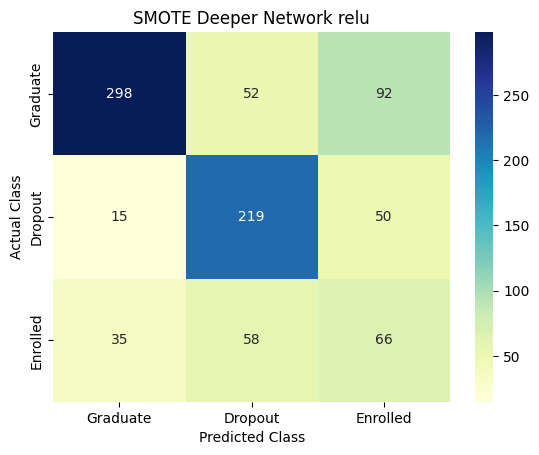

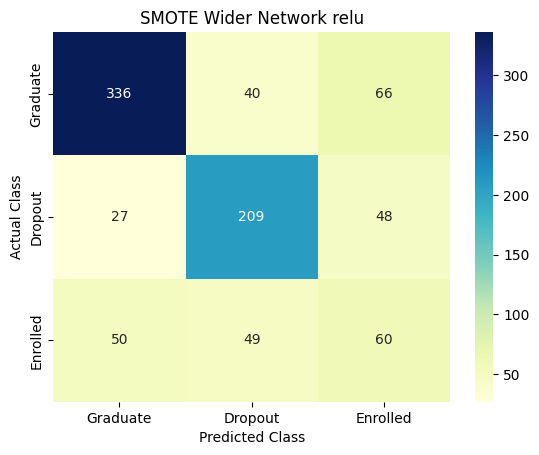

In [ ]:
#confusion matrix plot (relu)

#1) Deeper Network
class_names = ["Graduate", "Dropout", "Enrolled"]

conf_1_matrix = pd.DataFrame(data=conf_mlp_1, columns=class_names, index=class_names)

sns.heatmap(conf_1_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("SMOTE Deeper Network relu")
plt.show()

print()

#2) Wider Network
conf_2_matrix = pd.DataFrame(data=conf_mlp_2, columns=class_names, index=class_names)

sns.heatmap(conf_2_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("SMOTE Wider Network relu")
plt.show()

Tanh SMOTE testing confusion matrix PLOT

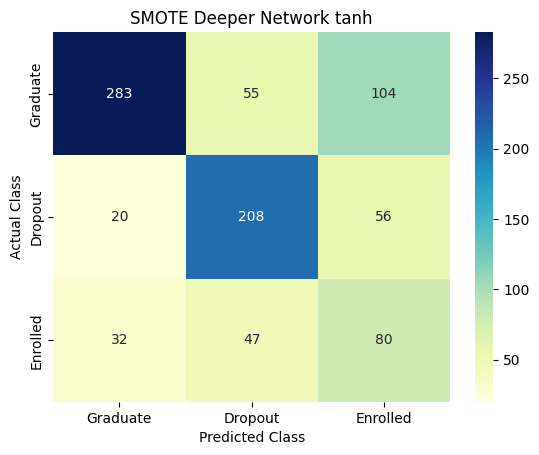

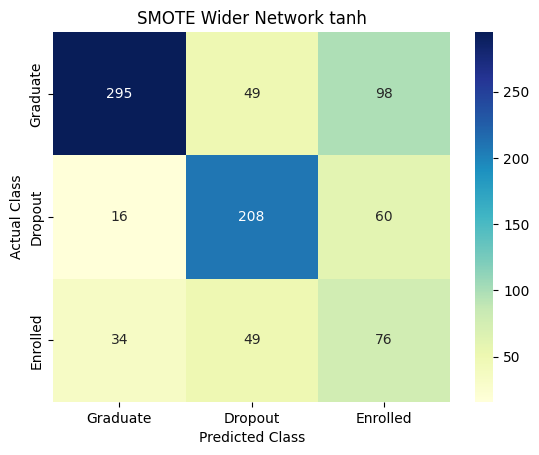

In [ ]:
#confusion matrix plot (tanh)

#1) Deeper Network
class_names = ["Graduate", "Dropout", "Enrolled"]

conf_1_matrix = pd.DataFrame(data=conf_mlp_1t, columns=class_names, index=class_names)

sns.heatmap(conf_1_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("SMOTE Deeper Network tanh")
plt.show()

print()

#2) Wider Network
conf_2_matrix = pd.DataFrame(data=conf_mlp_2t, columns=class_names, index=class_names)

sns.heatmap(conf_2_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title("SMOTE Wider Network tanh")
plt.show()

ReLU SMOTE classification report

In [ ]:
#classification report for training on smote data

#1) Deeper Network
classif_rep_1=classification_report(y_resampled_smote, y_pred_train_labels_1)
print(classif_rep_1)

print()

#2) Wider Network
classif_rep_2=classification_report(y_resampled_smote, y_pred_train_labels_2)
print(classif_rep_2)

              precision    recall  f1-score   support

           0       0.93      0.97      0.95      1767
           1       0.96      0.94      0.95      1767
           2       0.97      0.96      0.96      1767

    accuracy                           0.95      5301
   macro avg       0.95      0.95      0.95      5301
weighted avg       0.95      0.95      0.95      5301


              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1767
           1       0.98      0.97      0.98      1767
           2       0.99      0.97      0.98      1767

    accuracy                           0.98      5301
   macro avg       0.98      0.98      0.98      5301
weighted avg       0.98      0.98      0.98      5301



Tanh SMOTE training classification report

In [ ]:
#classification report for training on smote data

#1) Deeper Network
classif_rep_1=classification_report(y_resampled_smote, y_pred_train_labels_1t)
print(classif_rep_1)

print()

#2) Wider Network
classif_rep_2=classification_report(y_resampled_smote, y_pred_train_labels_2t)
print(classif_rep_2)

              precision    recall  f1-score   support

           0       0.97      0.97      0.97      1767
           1       0.98      0.97      0.98      1767
           2       0.96      0.98      0.97      1767

    accuracy                           0.97      5301
   macro avg       0.97      0.97      0.97      5301
weighted avg       0.97      0.97      0.97      5301


              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1767
           1       0.99      0.99      0.99      1767
           2       0.98      0.99      0.99      1767

    accuracy                           0.99      5301
   macro avg       0.99      0.99      0.99      5301
weighted avg       0.99      0.99      0.99      5301



ReLU SMOTE testing classification report

In [ ]:
#classification report for testing after training on smote data

#1) Deeper Network
classif_rep_1=classification_report(y_test, y_pred_test_labels_1)
print(classif_rep_1)

print()

#2) Wider Network
classif_rep_2=classification_report(y_test, y_pred_test_labels_2)
print(classif_rep_2)

              precision    recall  f1-score   support

           0       0.86      0.67      0.75       442
           1       0.67      0.77      0.71       284
           2       0.32      0.42      0.36       159

    accuracy                           0.66       885
   macro avg       0.61      0.62      0.61       885
weighted avg       0.70      0.66      0.67       885


              precision    recall  f1-score   support

           0       0.81      0.76      0.79       442
           1       0.70      0.74      0.72       284
           2       0.34      0.38      0.36       159

    accuracy                           0.68       885
   macro avg       0.62      0.62      0.62       885
weighted avg       0.69      0.68      0.69       885



tanh smote testing classification report

In [ ]:
#classification report for testing after training on smote data

#1) Deeper Network
classif_rep_1=classification_report(y_test, y_pred_test_labels_1t)
print(classif_rep_1)

print()

#2) Wider Network
classif_rep_2=classification_report(y_test, y_pred_test_labels_2t)
print(classif_rep_2)

              precision    recall  f1-score   support

           0       0.84      0.64      0.73       442
           1       0.67      0.73      0.70       284
           2       0.33      0.50      0.40       159

    accuracy                           0.65       885
   macro avg       0.62      0.63      0.61       885
weighted avg       0.70      0.65      0.66       885


              precision    recall  f1-score   support

           0       0.86      0.67      0.75       442
           1       0.68      0.73      0.71       284
           2       0.32      0.48      0.39       159

    accuracy                           0.65       885
   macro avg       0.62      0.63      0.61       885
weighted avg       0.70      0.65      0.67       885



ReLU SMOTE training loss CURVE

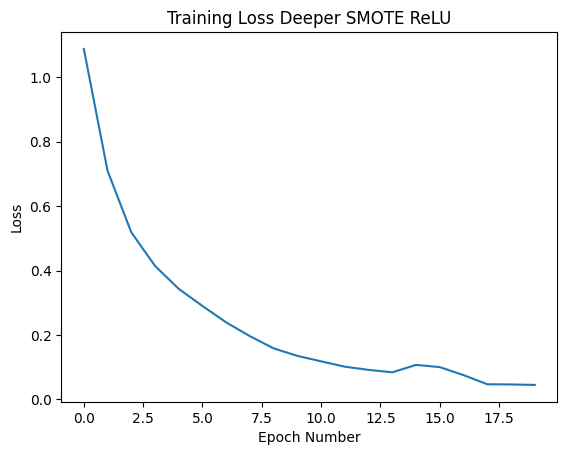

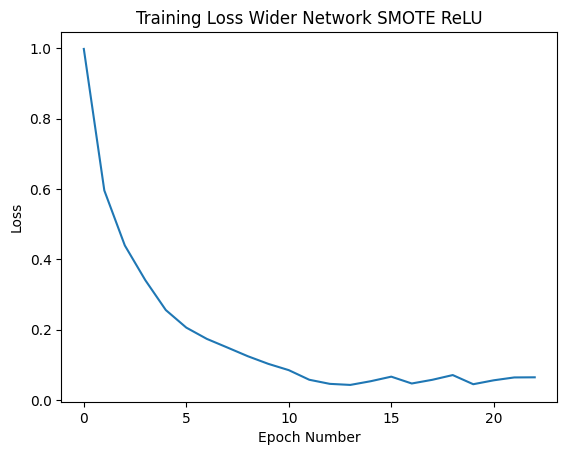

In [ ]:
#training loss on smote data

#1) Deeper Network
plt.plot(student_academic_success_model_1.loss_curve_)
plt.title("Training Loss Deeper SMOTE ReLU")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()

print()

#2) Wider Network
plt.plot(student_academic_success_model_2.loss_curve_)
plt.title("Training Loss Wider Network SMOTE ReLU")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()

Tanh SMOTE training loss CURVE

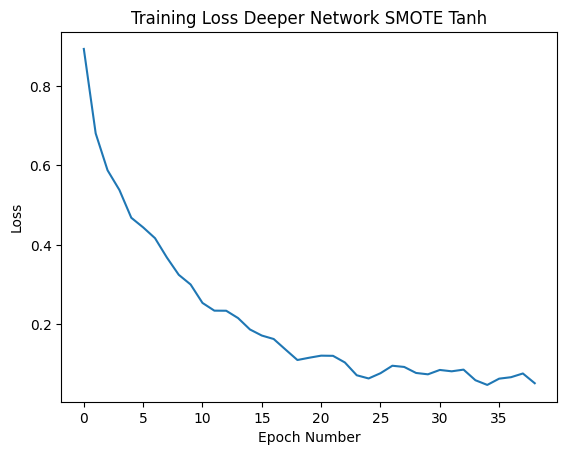

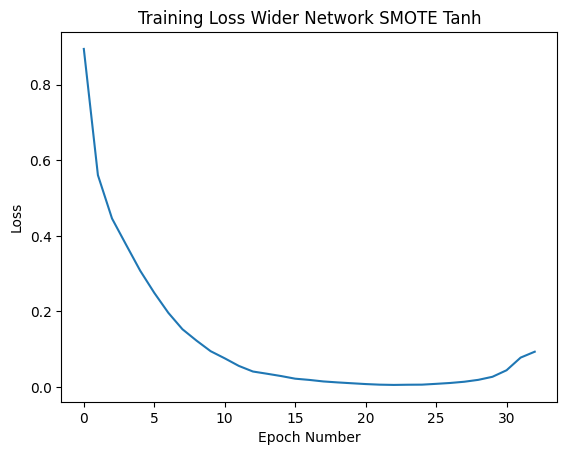

In [ ]:
#training loss on smote data

#1) Deeper Network
plt.plot(student_academic_success_model_1t.loss_curve_)
plt.title("Training Loss Deeper Network SMOTE Tanh")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()

print()

#2) Wider Network
plt.plot(student_academic_success_model_2t.loss_curve_)
plt.title("Training Loss Wider Network SMOTE Tanh")
plt.xlabel("Epoch Number")
plt.ylabel("Loss")
plt.show()